# Customer behaviour and target definitions

Source: Chen (2012), Online Retail II, UCI, CC BY 4.0. Run the pipeline before this notebook. Figures describe historical purchases, not loyalty membership or causal offer effects.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
data=pd.read_parquet(ROOT/'data/processed/customer_snapshots.parquet')
data.groupby('snapshot_date').agg(customers=('customer_id','nunique'),inactivity_rate=('inactive_90','mean'),mean_future_spending=('future_spend_90','mean'))

,customers,inactivity_rate,mean_future_spending
snapshot_date,,,
2010-06-01,2652,0.499623,558.031953
2010-09-01,2822,0.379872,796.523278
2010-12-01,3465,0.619625,402.551847
2011-03-01,3338,0.576393,416.522418
2011-06-01,2658,0.500376,575.051275
2011-09-01,2768,0.393064,867.566796


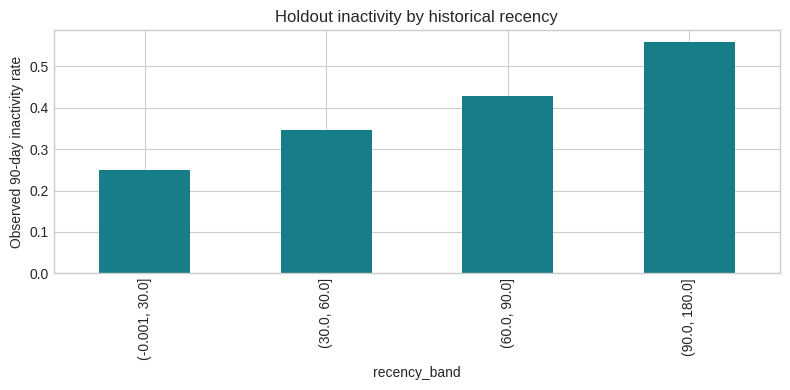

In [3]:
latest=data[data.snapshot_date==data.snapshot_date.max()].copy()
latest['recency_band']=pd.cut(latest.recency_days,[0,30,60,90,180],include_lowest=True)
latest.groupby('recency_band',observed=True).inactive_90.mean().plot.bar(figsize=(8,4),color='#177e89',title='Holdout inactivity by historical recency')
plt.ylabel('Observed 90-day inactivity rate');plt.tight_layout();plt.show()

## Interpretation
Compare against the baseline and report limitations. No purchase for 90 days does not prove permanent churn. Large wholesale purchases can dominate spending error. Survival diagnostics can reject proportional hazards; the Cox model is exploratory if that assumption fails. Retention priority is a heuristic requiring an experiment before claiming campaign benefit.